# Fairness–Accuracy Pareto Frontier

Compare the eight held-out test configurations using predictive Accuracy (higher is better) and absolute Equal Opportunity Difference (EOD; lower is better). A configuration is Pareto-optimal when no other configuration is at least as good on both metrics and strictly better on one.

## Load final test results

Read the consolidated results produced by `06_final_evaluation.ipynb`. Validation scores and separate Exponentiated Gradient files are not included.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
results_dir = PROJECT_ROOT / "results"

pareto_data = pd.read_csv(results_dir / "final_test_comparison.csv")
assert len(pareto_data) == 8, "Expected eight configurations from final evaluation."
display(pareto_data[["Model", "Strategy", "Accuracy", "EOD"]].round(4))

,Model,Strategy,Accuracy,EOD
0,Logistic Regression,Baseline,0.8081,0.0342
1,Logistic Regression,Reweighing,0.8058,0.0312
2,Logistic Regression,Threshold Optimization,0.8034,0.0117
3,Logistic Regression,ExponentiatedGradient,0.8066,0.0155
4,Random Forest,Baseline,0.7931,0.0180
5,Random Forest,Reweighing,0.7940,0.0118
6,Random Forest,Threshold Optimization,0.7856,0.0080
7,Random Forest,ExponentiatedGradient,0.7945,0.0279


## Identify nondominated configurations

A point is dominated if another configuration has at least as high Accuracy and at most as high EOD, with a strict improvement in at least one metric. Compare all configurations together rather than constructing separate frontiers by model.

In [2]:
pareto_data["Pareto Optimal"] = True

for i, row in pareto_data.iterrows():
    dominated = (
        (pareto_data["Accuracy"] >= row["Accuracy"])
        & (pareto_data["EOD"] <= row["EOD"])
        & (
            (pareto_data["Accuracy"] > row["Accuracy"])
            | (pareto_data["EOD"] < row["EOD"])
        )
    )
    pareto_data.loc[i, "Pareto Optimal"] = not dominated.any()

frontier = pareto_data.loc[pareto_data["Pareto Optimal"]].sort_values("EOD")
display(pareto_data[["Model", "Strategy", "Accuracy", "EOD", "Pareto Optimal"]].round(4))

,Model,Strategy,Accuracy,EOD,Pareto Optimal
0,Logistic Regression,Baseline,0.8081,0.0342,True
1,Logistic Regression,Reweighing,0.8058,0.0312,False
2,Logistic Regression,Threshold Optimization,0.8034,0.0117,True
3,Logistic Regression,ExponentiatedGradient,0.8066,0.0155,True
4,Random Forest,Baseline,0.7931,0.0180,False
5,Random Forest,Reweighing,0.7940,0.0118,False
6,Random Forest,Threshold Optimization,0.7856,0.0080,True
7,Random Forest,ExponentiatedGradient,0.7945,0.0279,False


## Visualize the trade-off

Colors identify mitigation strategies; marker shapes distinguish the two classifiers. Larger outlined markers and labels identify nondominated configurations. The dashed line connects the Pareto frontier in ascending EOD order.

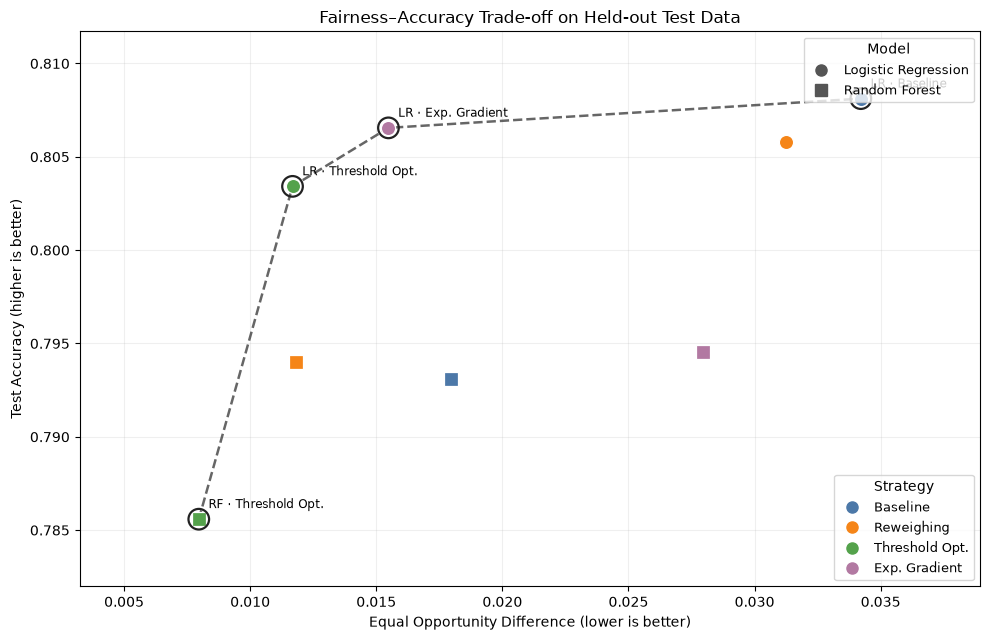

In [ ]:
strategy_colors = {
    "Baseline": "#4C78A8",
    "Reweighing": "#F58518",
    "Threshold Optimization": "#54A24B",
    "ExponentiatedGradient": "#B279A2",
}
model_markers = {"Logistic Regression": "o", "Random Forest": "s"}
strategy_short = {
    "Baseline": "Baseline",
    "Reweighing": "Reweighing",
    "Threshold Optimization": "Threshold Opt.",
    "ExponentiatedGradient": "Exp. Gradient",
}

fig, ax = plt.subplots(figsize=(10, 6.5))

for (strategy, model), group in pareto_data.groupby(["Strategy", "Model"], sort=False):
    ax.scatter(
        group["EOD"], group["Accuracy"],
        color=strategy_colors[strategy], marker=model_markers[model],
        s=105, edgecolor="white", linewidth=0.9, zorder=3,
    )

ax.plot(
    frontier["EOD"], frontier["Accuracy"],
    linestyle="--", linewidth=1.8, color="#333333", alpha=0.75,
    label="Pareto frontier", zorder=2,
)
ax.scatter(
    frontier["EOD"], frontier["Accuracy"],
    s=220, facecolors="none", edgecolors="#222222", linewidths=1.6, zorder=4,
)

for _, row in frontier.iterrows():
    short_model = "LR" if row["Model"] == "Logistic Regression" else "RF"
    ax.annotate(
        f"{short_model} · {strategy_short[row['Strategy']]}",
        (row["EOD"], row["Accuracy"]),
        xytext=(7, 8), textcoords="offset points", fontsize=8.5,
    )

from matplotlib.lines import Line2D
strategy_handles = [
    Line2D([0], [0], marker="o", linestyle="", markersize=8,
           color=color, label=strategy_short[strategy])
    for strategy, color in strategy_colors.items()
]
model_handles = [
    Line2D([0], [0], marker=marker, linestyle="", markersize=8,
           color="#555555", label=model)
    for model, marker in model_markers.items()
]
legend1 = ax.legend(handles=strategy_handles, title="Strategy", loc="lower right", fontsize=9)
ax.add_artist(legend1)
ax.legend(handles=model_handles, title="Model", loc="upper right", fontsize=9)

ax.set_xlabel("Equal Opportunity Difference (lower is better)")
ax.set_ylabel("Test Accuracy (higher is better)")
ax.set_title("Fairness–Accuracy Trade-off on Held-out Test Data")
ax.grid(alpha=0.2)
ax.margins(x=0.18, y=0.16)
fig.tight_layout()
fig.savefig(results_dir / "pareto_frontier.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation

Nondominated points represent distinct observed compromises between Accuracy and EOD; none is universally best across both objectives. This frontier is descriptive for the eight evaluated configurations and does not imply statistical separation between neighboring points. Bootstrap uncertainty is reported in `06_final_evaluation.ipynb`.